**Nama: Yuma Hazza Yuditama <br>**
**NIM: 24060124120035 <br>**
**Lab: C1 <br>**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# mengatur gaya visualisasi seaborn
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Memuat Dataset

In [3]:
df = pd.read_csv("/kaggle/input/datasets/aamir28/student-sleep-screen-time-and-academic-performance/student_sleep_screen_time_academic_performance.csv")
df

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,STU2496,18,Male,4,Humanities,Dormitory,Intermediate,22.5,7.5,0.4,...,0,8.0,4,7.0,4.0,10.1,90.8,No,Fall,3.21
496,STU2497,22,Male,2,Health Sciences,Dormitory,Night Owl,0.8,6.2,2.4,...,2,10.0,4,6.0,5.0,17.2,70.7,No,Spring,2.87
497,STU2498,20,Female,5,Health Sciences,With Family,Early Bird,22.0,7.1,1.1,...,3,10.0,1,8.0,2.0,21.7,79.8,No,Spring,3.54
498,STU2499,22,M,3,STEM,Dormitory,Early Bird,23.6,9.0,2.3,...,0,10.0,7,7.0,1.0,19.3,97.8,Yes,Spring,3.67


In [4]:
print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

Ukuran dataset: 500 baris, 25 kolom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    object 
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    object 
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    object 
 5   residence_type             500 non-null    object 
 6   chronotype                 500 non-null    object 
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    object 
 13  device_free_before_bed     491 non-null    object 

In [6]:
df.describe()

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,cgpa
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,494.000000,500.000000,485.000000,486.000000,500.0000,500.000000,493.000000
mean,20.260000,2.954000,12.778200,6.608200,1.540600,38.388000,5.827000,1.502000,1.458000,7.271255,3.666000,5.758763,5.176955,16.5714,79.247200,2.833834
std,1.994079,1.405644,10.772656,1.435784,0.965441,23.573478,2.046193,1.273279,1.331082,2.131409,2.277019,1.981722,2.033119,6.9279,11.983513,0.334771
min,17.000000,1.000000,0.000000,1.500000,-1.000000,0.000000,0.500000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.0000,34.600000,1.890000
25%,19.000000,2.000000,1.100000,5.700000,0.900000,22.000000,4.475000,1.000000,0.000000,6.000000,2.000000,4.000000,4.000000,12.1000,70.775000,2.620000
50%,20.000000,3.000000,21.500000,6.600000,1.500000,35.500000,5.800000,1.000000,1.000000,7.000000,4.000000,6.000000,5.000000,16.3000,79.800000,2.850000
75%,22.000000,4.000000,22.800000,7.700000,2.200000,54.000000,7.200000,2.000000,2.000000,9.000000,6.000000,7.000000,7.000000,20.3250,87.925000,3.050000
max,27.000000,5.000000,24.000000,10.500000,4.400000,240.000000,19.500000,7.000000,7.000000,10.000000,7.000000,10.000000,10.000000,88.5000,100.000000,3.950000


# 2. Cek Duplikasi

In [7]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
495    False
496    False
497    False
498    False
499    False
Length: 500, dtype: bool

In [8]:
duplicate_count = df.duplicated().sum()
print(f"Jumlah baris duplikat: {duplicate_count}")

Jumlah baris duplikat: 0


**Tidak ada baris yang terduplikasi di dataset**. Jika ada data duplikat, sebaiknya dihapus (di-drop).

In [9]:
if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Baris duplikat telah dihapus.")
else:
    print("Tidak ada data duplikat.")

Tidak ada data duplikat.


# 3. Cek Missing Value

In [10]:
df.isnull()

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
496,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
497,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
498,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [11]:
missing_val = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df) * 100)
missing_df = pd.DataFrame(
    {'Jumlah Missing': missing_val,
     'Persentase (%)': missing_percent}
)

print("Kolom yang ada missing value:")
display(missing_df[missing_df['Jumlah Missing'] > 0])

Kolom yang ada missing value:


,Jumlah Missing,Persentase (%)
device_free_before_bed,9,1.8
sleep_quality_score,6,1.2
energy_level,15,3.0
concentration_difficulty,14,2.8
cgpa,7,1.4


# 4. Imputasi Missing Value

In [12]:
# untuk kolom numerik, bisa diisi dengan median
numeric_cols_with_na = [
    'sleep_quality_score',
    'energy_level',
    'concentration_difficulty'
]


for col in numeric_cols_with_na:
    if col in df.columns and df[col].isnull().sum() > 0:
        
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        
        print(f"Imputasi kolom {col} menggunakan median: {median_val}")

# untuk kolom kategorikal, bisa diisi dengan modus
cat_cols_with_na = ['device_free_before_bed']
for col in cat_cols_with_na:
  if col in df.columns and df[col].isnull().sum() > 0:
      
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
      
    print(
        f"Imputasi kolom kategorikal '{col}' menggunakan modus: {mode_val}"
    )

print(
    '\nSisa missing value setelah imputasi:',
    df.isnull().sum().sum(),
    '\n',
)

Imputasi kolom sleep_quality_score menggunakan median: 7.0
Imputasi kolom energy_level menggunakan median: 6.0
Imputasi kolom concentration_difficulty menggunakan median: 5.0
Imputasi kolom kategorikal 'device_free_before_bed' menggunakan modus: No

Sisa missing value setelah imputasi: 7 



In [13]:
# Kolom CGPA adalah target variable, bisa di-drop saja
df.dropna(inplace=True)

print(
    '\nSisa missing value:',
    df.isnull().sum().sum(),
    '\n',
)


Sisa missing value: 0 



# 5. Membetulkan Fitur yang Bermasalah

Fitur gender masih memiliki value yang beragam

In [14]:
df['gender'].unique()

array(['Male', 'Female', 'F', 'male', 'Prefer not to say', 'M',
       'Non-binary', 'female'], dtype=object)

In [15]:
GENDERS = {
    'Male': 'Male',
    'male': 'Male',
    'M': 'Male',
    'Female': 'Female',
    'female': 'Female',
    'F': 'Female',
    'Prefer not to say': 'Prefer not to say',
    'Non-binary': 'Non-binary'
}

df['gender_fix'] = df['gender'].map(GENDERS)

df

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa,gender_fix
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99,Male
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88,Female
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15,Male
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27,Female
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74,Female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,STU2496,18,Male,4,Humanities,Dormitory,Intermediate,22.5,7.5,0.4,...,8.0,4,7.0,4.0,10.1,90.8,No,Fall,3.21,Male
496,STU2497,22,Male,2,Health Sciences,Dormitory,Night Owl,0.8,6.2,2.4,...,10.0,4,6.0,5.0,17.2,70.7,No,Spring,2.87,Male
497,STU2498,20,Female,5,Health Sciences,With Family,Early Bird,22.0,7.1,1.1,...,10.0,1,8.0,2.0,21.7,79.8,No,Spring,3.54,Female
498,STU2499,22,M,3,STEM,Dormitory,Early Bird,23.6,9.0,2.3,...,10.0,7,7.0,1.0,19.3,97.8,Yes,Spring,3.67,Male


In [16]:
# Menghapus kolom gender yang lama
df.drop(columns=['gender'], inplace=True)

# 6. Deteksi dan Penanganan Outlier

In [17]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(numeric_cols)

['age', 'year_of_study', 'avg_bedtime_hour', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'pre_sleep_screen_time_min', 'daily_screen_time_hours', 'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score', 'exercise_days_per_week', 'energy_level', 'concentration_difficulty', 'weekly_study_hours', 'class_attendance_percent', 'cgpa']


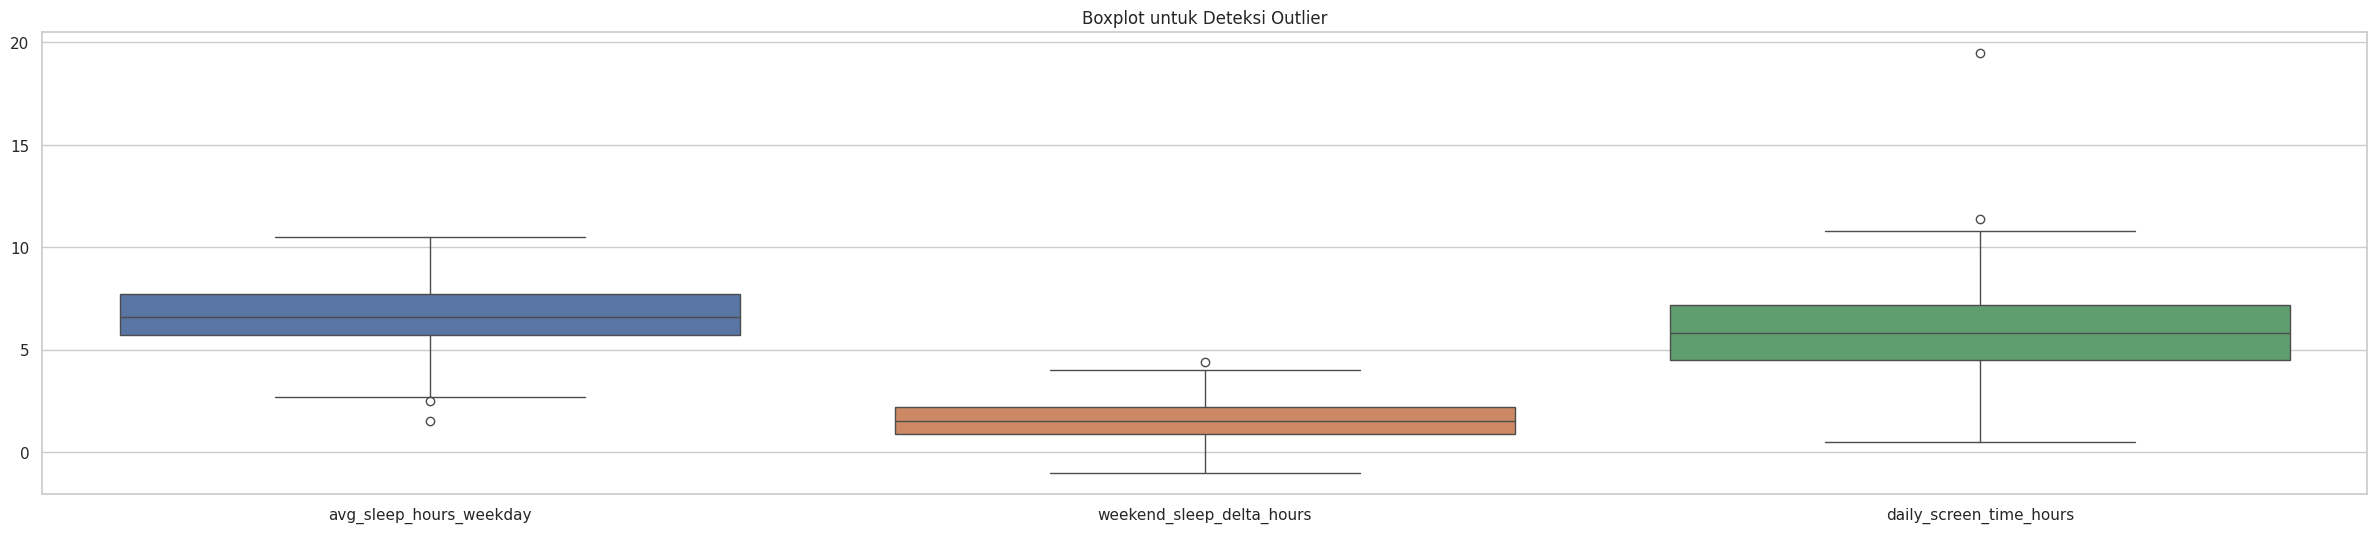

In [18]:
# Visualisasi Boxplot sebelum penanganan outlier untuk beberapa kolom
plt.figure(figsize=(30, 6))
sns.boxplot(data=df[['avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'daily_screen_time_hours']])
plt.title('Boxplot untuk Deteksi Outlier')
plt.show()

In [19]:
# Menghitung IQR dan menangani outlier (misalnya dengan metode capping / clipping)
for col in ['daily_screen_time_hours', 'weekly_study_hours']:
  if col in numeric_cols:
    print(f"Menangani outlier di kolom {col}")
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"Q1 : {Q1}")
    print(f"Q2 : {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower bound : {lower_bound}")
    print(f"Upper bound : {upper_bound}")
      
    outliers_count = df[
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ].shape[0]
    print(f"Kolom '{col}': ditemukan {outliers_count} outlier.")

    # Capping nilai outlier agar batasnya mentok di lower/upper bound
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

    print("=========================================================")


Menangani outlier di kolom daily_screen_time_hours
Q1 : 4.5
Q2 : 7.2
IQR: 2.7
Lower bound : 0.4499999999999993
Upper bound : 11.25
Kolom 'daily_screen_time_hours': ditemukan 2 outlier.
Menangani outlier di kolom weekly_study_hours
Q1 : 12.2
Q2 : 20.4
IQR: 8.2
Lower bound : -0.09999999999999964
Upper bound : 32.699999999999996
Kolom 'weekly_study_hours': ditemukan 3 outlier.


# 7. Analisis Korelasi

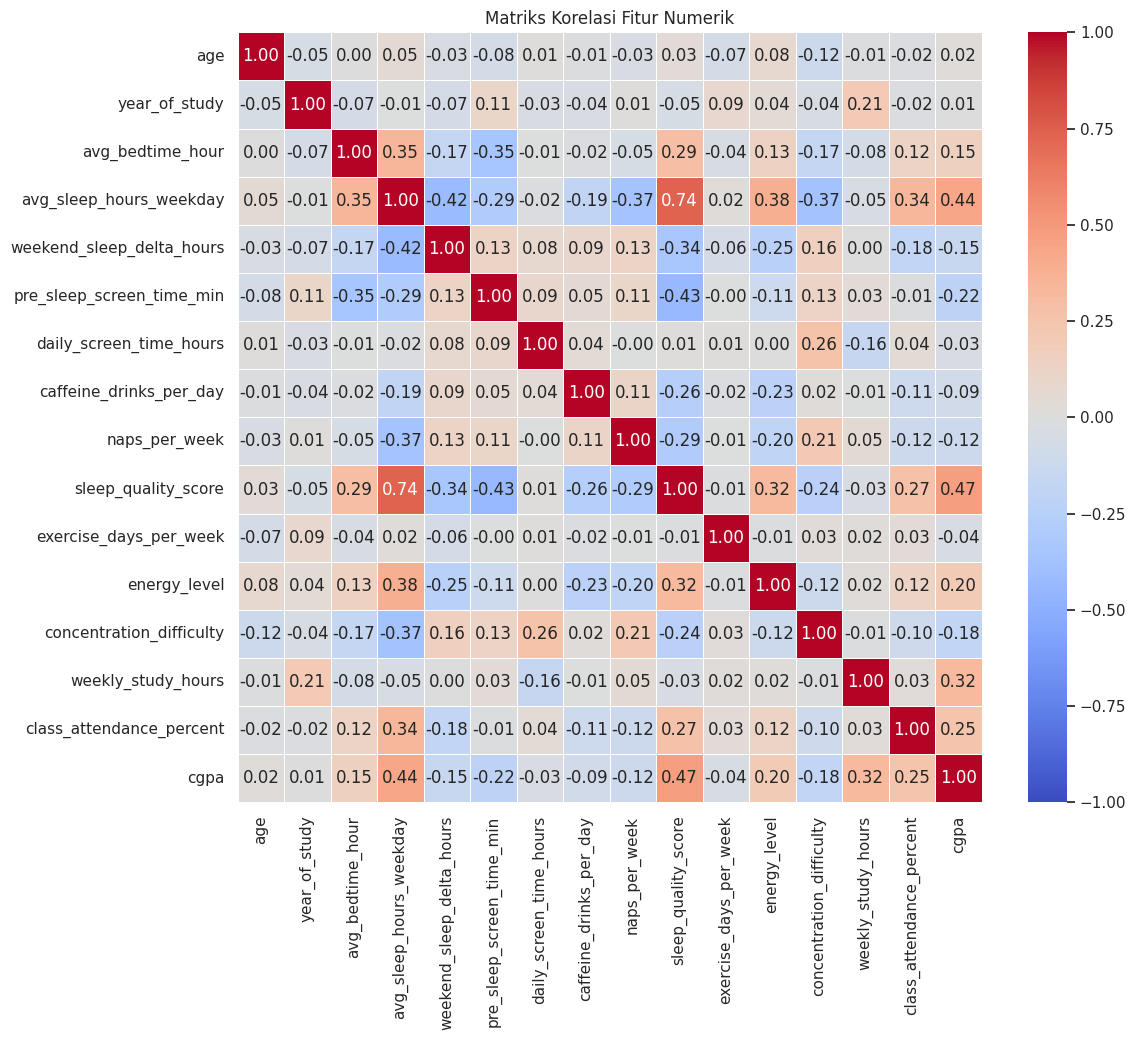

In [20]:
plt.figure(figsize=(12, 10))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5,
    vmin=-1.0, vmax=1.0
)
plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

# 8. Analisis Bivariat

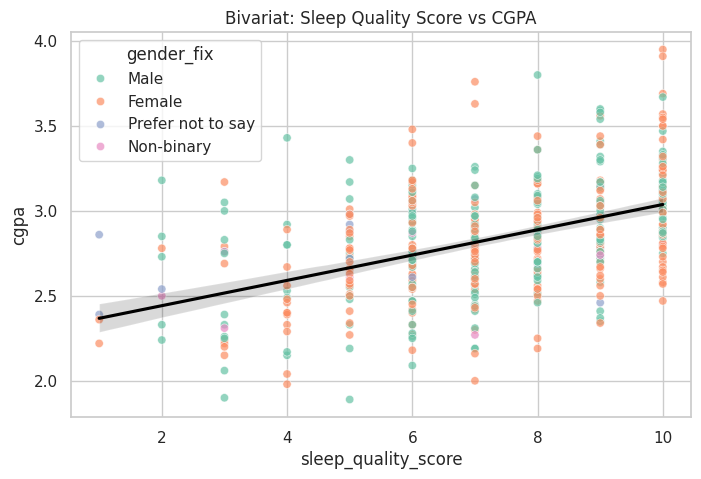

In [21]:
# Contoh 1: Hubungan antara daily_screen_time_hours vs cgpa (Scatter Plot dengan garis regresi)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='sleep_quality_score',
    y='cgpa',
    hue='gender_fix',
    alpha=0.7,
    palette='Set2',
)
sns.regplot(
    data=df,
    x='sleep_quality_score',
    y='cgpa',
    scatter=False,
    color='black',
)
plt.title('Bivariat: Sleep Quality Score vs CGPA')
plt.show()

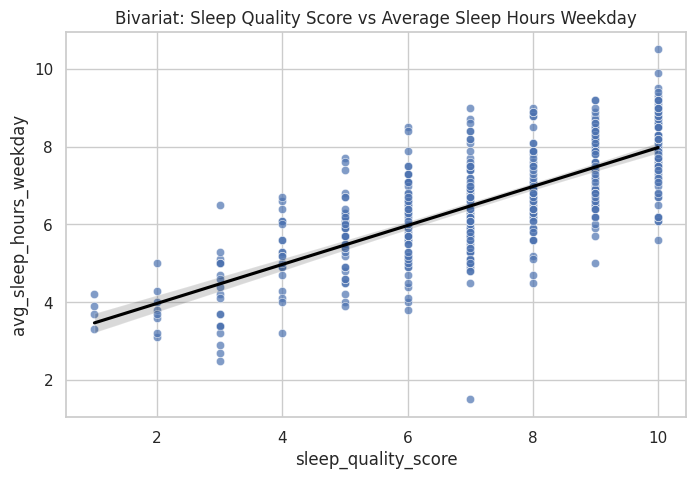

In [22]:
# Contoh 1: Hubungan antara daily_screen_time_hours vs cgpa (Scatter Plot dengan garis regresi)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='sleep_quality_score',
    y='avg_sleep_hours_weekday',
    # hue='gender_fix',
    alpha=0.7,
    # palette='Set2',
)
sns.regplot(
    data=df,
    x='sleep_quality_score',
    y='avg_sleep_hours_weekday',
    scatter=False,
    color='black',
)
plt.title('Bivariat: Sleep Quality Score vs Average Sleep Hours Weekday')
plt.show()

# 

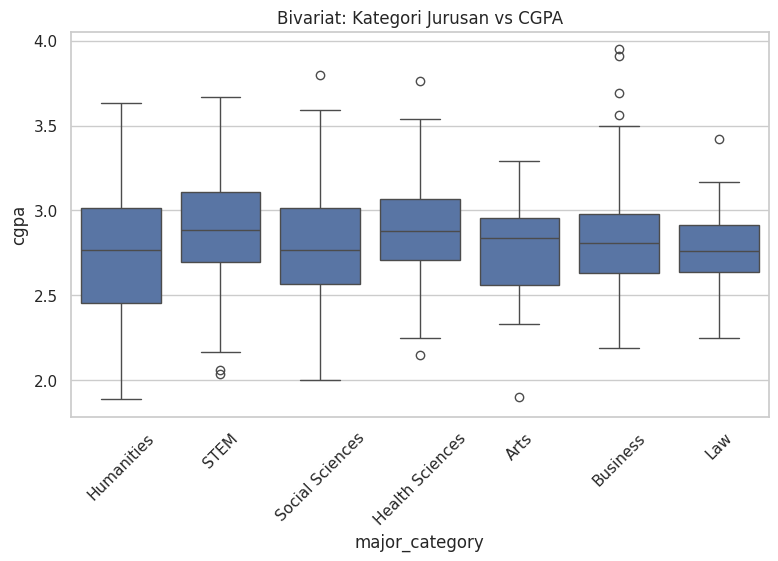

In [23]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='major_category', y='cgpa')
plt.title('Bivariat: Kategori Jurusan vs CGPA')
plt.xticks(rotation=45)
plt.show()

# 9. Analisis Multivariat (Pairplot)

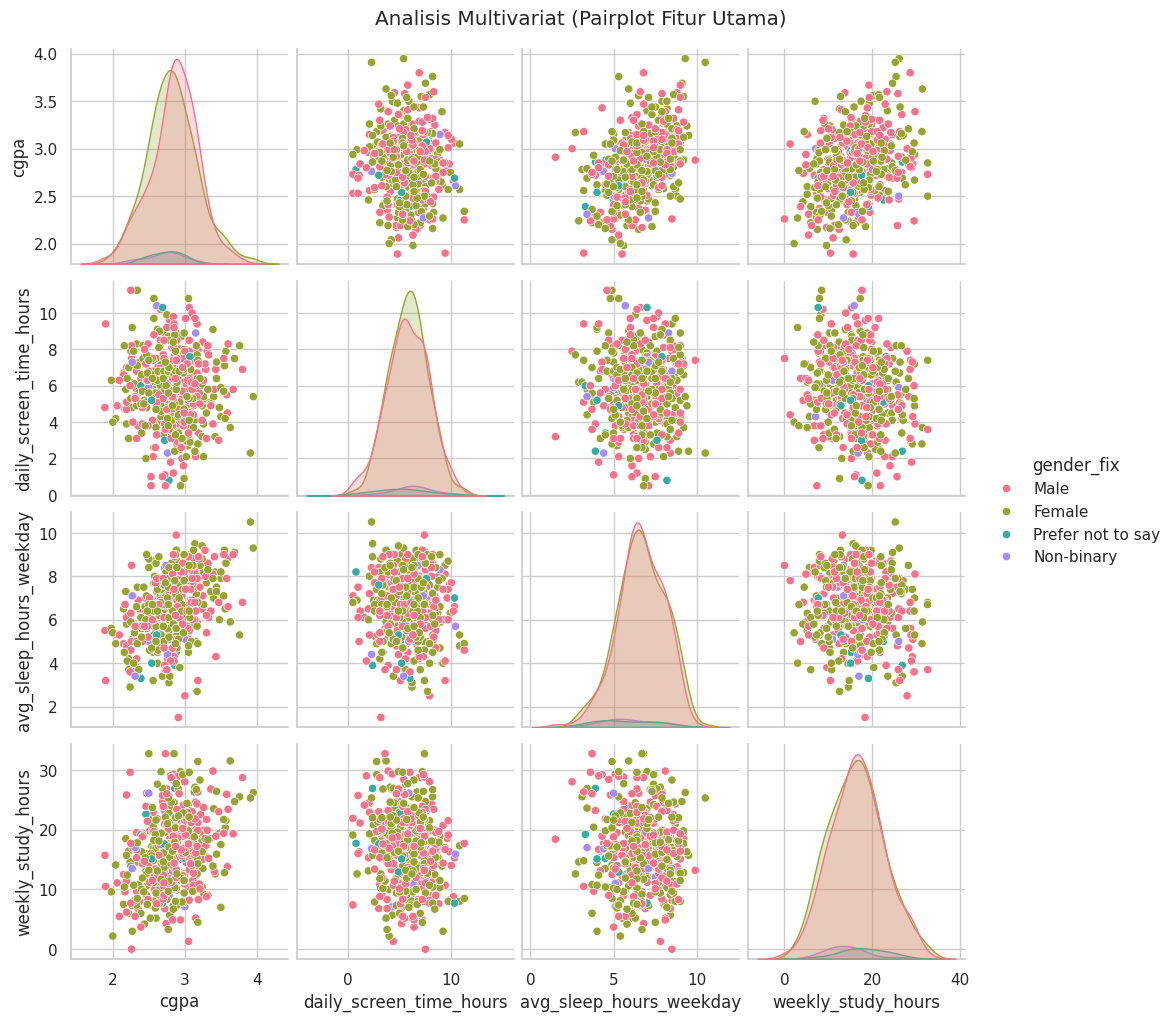

In [24]:
# Memilih beberapa fitur numerik utama agar plot mudah dibaca
multivar_cols = [
    'cgpa',
    'daily_screen_time_hours',
    'avg_sleep_hours_weekday',
    'weekly_study_hours',
]
sns.pairplot(
    df[multivar_cols + ['gender_fix']].dropna(),
    hue='gender_fix',
    diag_kind='kde',
    palette='husl',
)
plt.suptitle('Analisis Multivariat (Pairplot Fitur Utama)', y=1.02)
plt.show()


# 10. Cek Skewness

In [25]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
skewness_values = df[numeric_cols].skew()

skew_df = pd.DataFrame(
    {'Skewness': skewness_values, 'Tipe Distribusi': ''}
)
for idx, val in skewness_values.items():
  if val > 1:
    skew_df.loc[idx, 'Tipe Distribusi'] = 'High Positive Skew'
  elif val < -1:
    skew_df.loc[idx, 'Tipe Distribusi'] = 'High Negative Skew'
  else:
    skew_df.loc[idx, 'Tipe Distribusi'] = 'Relatif Normal'

print(skew_df, '\n')

                           Skewness     Tipe Distribusi
age                        0.408895      Relatif Normal
year_of_study              0.018355      Relatif Normal
avg_bedtime_hour          -0.166112      Relatif Normal
avg_sleep_hours_weekday   -0.279077      Relatif Normal
weekend_sleep_delta_hours -0.045637      Relatif Normal
pre_sleep_screen_time_min  1.558039  High Positive Skew
daily_screen_time_hours   -0.047731      Relatif Normal
caffeine_drinks_per_day    0.896914      Relatif Normal
naps_per_week              1.032071  High Positive Skew
sleep_quality_score       -0.584167      Relatif Normal
exercise_days_per_week    -0.027532      Relatif Normal
energy_level              -0.139013      Relatif Normal
concentration_difficulty   0.095079      Relatif Normal
weekly_study_hours         0.147268      Relatif Normal
class_attendance_percent  -0.213654      Relatif Normal
cgpa                       0.087550      Relatif Normal 



**NOTE: MODEL BIASANYA CUMA MAU "MAKAN" DATA YANG BERDISTRIBUSI NORMAL, KALO SKEW GK ENAK KATANYA**
<br>
Bisa melakukan transformasi log untuk "menormalkan" datanya.

In [26]:
df['pre_sleep_screen_time_min_log'] = np.log1p(df['pre_sleep_screen_time_min'])

In [27]:
print(f"Before: {df['pre_sleep_screen_time_min'].skew()}")
print(f"After: {df['pre_sleep_screen_time_min_log'].skew()}")

Before: 1.558039277277384
After: -1.9067323444893072


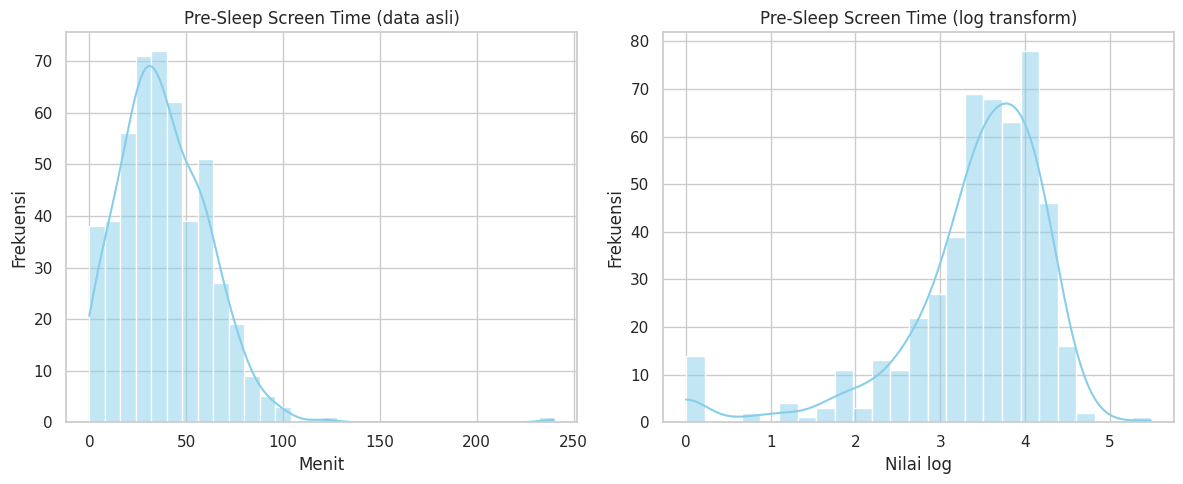

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['pre_sleep_screen_time_min'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Pre-Sleep Screen Time (data asli)')
axes[0].set_xlabel('Menit')
axes[0].set_ylabel('Frekuensi')

sns.histplot(df['pre_sleep_screen_time_min_log'], kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Pre-Sleep Screen Time (log transform)')
axes[1].set_xlabel('Nilai log')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

mari kita coba pakai fungsi akar untuk menormalisasi distribusi datanya

In [29]:
df['pre_sleep_screen_time_min_sqrt'] = np.sqrt(df['pre_sleep_screen_time_min'])

In [30]:
print(f"Data asli: {df['pre_sleep_screen_time_min'].skew()}")
print(f"Log-transform: {df['pre_sleep_screen_time_min_log'].skew()}")
print(f"Fungsi akar: {df['pre_sleep_screen_time_min_sqrt'].skew()}")

Data asli: 1.558039277277384
Log-transform: -1.9067323444893072
Fungsi akar: -0.43499652585073506


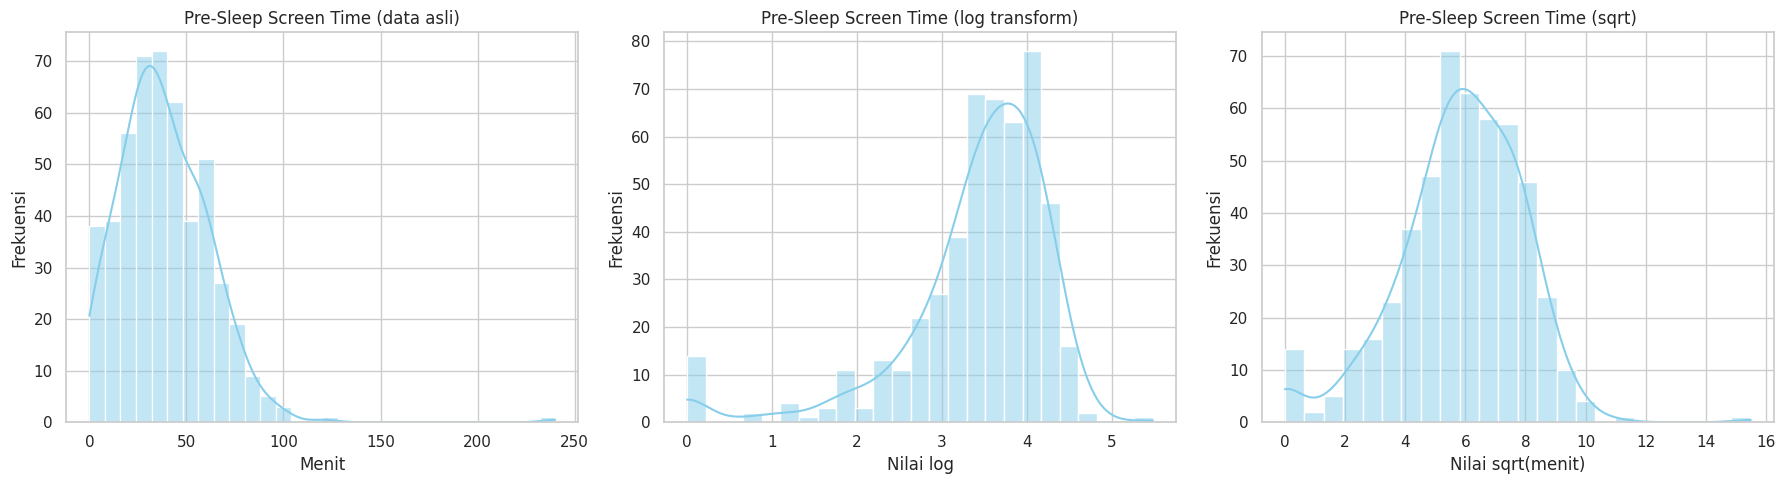

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['pre_sleep_screen_time_min'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Pre-Sleep Screen Time (data asli)')
axes[0].set_xlabel('Menit')
axes[0].set_ylabel('Frekuensi')

sns.histplot(df['pre_sleep_screen_time_min_log'], kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Pre-Sleep Screen Time (log transform)')
axes[1].set_xlabel('Nilai log')
axes[1].set_ylabel('Frekuensi')

sns.histplot(df['pre_sleep_screen_time_min_sqrt'], kde=True, ax=axes[2], color='skyblue')
axes[2].set_title('Pre-Sleep Screen Time (sqrt)')
axes[2].set_xlabel('Nilai sqrt(menit)')
axes[2].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

NICE!

# 11. Encoding Categorical Features

In [32]:
df.select_dtypes(include='object')

,student_id,major_category,residence_type,chronotype,primary_device,device_free_before_bed,has_part_time_job,semester_type,gender_fix
0,STU2001,Humanities,With Family,Early Bird,Tablet,No,No,Spring,Male
1,STU2002,STEM,Dormitory,Intermediate,Laptop,Yes,No,Summer,Female
2,STU2003,Social Sciences,With Family,Intermediate,Smartphone,No,Yes,Spring,Male
3,STU2004,Humanities,Off-campus Apartment,Night Owl,Laptop,No,No,Fall,Female
4,STU2005,Social Sciences,Off-campus Apartment,Early Bird,Smartphone,No,No,Summer,Female
...,...,...,...,...,...,...,...,...,...
495,STU2496,Humanities,Dormitory,Intermediate,Smartphone,Yes,No,Fall,Male
496,STU2497,Health Sciences,Dormitory,Night Owl,Smartphone,No,No,Spring,Male
497,STU2498,Health Sciences,With Family,Early Bird,Laptop,No,No,Spring,Female
498,STU2499,STEM,Dormitory,Early Bird,Laptop,No,Yes,Spring,Male


In [33]:
df.drop(columns=['student_id'], inplace=True) # student id dihapus aja, kenapa ya...?

'''
Jawaban saya:
Kolom student id dihapus karena kolom tersebut hanya sebagai identifier student aja. 
Tidak ada informasi baru yang didapat dari kolom tersebut.
Dan juga untuk meringankan beban komputasi, maka sebaiknya dihapus aja.
'''

'\nJawaban saya:\nKolom student id dihapus karena kolom tersebut hanya sebagai identifier student aja. \nTidak ada informasi baru yang didapat dari kolom tersebut.\nDan juga untuk meringankan beban komputasi, maka sebaiknya dihapus aja.\n'

## 11.1. Nominal

Fitur kategorikal nominal adalah 'major_category', 'residence_type', 'chronotype', 'primary_device', 'semester_type', 'device_free_before_bed', 'has_part_time_job', dan 'gender_fix'. KEBETULAN, memang semuanya nominal.*
<br>
*Apakah ada yang berinterpretasi lain?
<br>
Umumnya, tipe data nominal di-encode dengan metode One Hot Encoding

In [34]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(cat_cols)

['major_category', 'residence_type', 'chronotype', 'primary_device', 'device_free_before_bed', 'has_part_time_job', 'semester_type', 'gender_fix']


In [35]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
encoded_array = encoder.fit_transform(df[cat_cols])

In [36]:
encoded_array.shape

(493, 20)

In [37]:
encoded_cols = encoder.get_feature_names_out(cat_cols)
encoded_df = pd.DataFrame(encoded_array, columns=encoded_cols, index=df.index)

df_dropped = df.drop(columns=cat_cols)

df_final = pd.concat([df_dropped, encoded_df], axis=1)

In [38]:
df_final

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,...,chronotype_Night Owl,primary_device_Smartphone,primary_device_Tablet,device_free_before_bed_Yes,has_part_time_job_Yes,semester_type_Spring,semester_type_Summer,gender_fix_Male,gender_fix_Non-binary,gender_fix_Prefer not to say
0,21,3,22.3,7.6,2.0,12,7.1,2,0,10.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,20,2,23.1,5.9,2.7,49,5.7,1,3,7.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,20,4,23.4,8.4,1.8,22,2.3,2,1,9.0,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
3,22,1,0.9,5.1,2.4,32,4.8,1,3,6.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,23,4,23.4,5.9,2.0,27,4.5,4,2,7.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,18,4,22.5,7.5,0.4,37,5.0,2,0,8.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
496,22,2,0.8,6.2,2.4,34,6.4,2,2,10.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
497,20,5,22.0,7.1,1.1,4,5.7,0,3,10.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
498,22,3,23.6,9.0,2.3,26,5.8,1,0,10.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0


CURSE OF DIMENSIONALITY!!!

Komentar dari saya:
Kenapa di tabel tersebut, indexnya sampe 499? Padahal rows-nya hanya 493.
Harusnya setelah menghapus suatu baris, pake **df.reset_index(drop=True)** biar indexnya reset lagi (menyesuaikan jumlah rows). Tapi yaa, saya ngikutin modulnya aja, gak disuruh benerin indexnya juga.

## 11.2. Ordinal

KEBETULAN, datasetnya ga ada kategorikal yang ordinal, ordinalnya udah dalam bentuk numerik semua. Jadi udah aman. Ada yang bisa sebutkan ordinalnya itu mana aja?

Jawaban:
Menurut saya, kolom yang termasuk ordinal tuh kolom year_of_study. Karena kolom ini walaupun tipe data-nya integer, tapi kolom ini hanya menggambarkan tingkat tahun/masa belajar yang telah dilalui oleh si student.

# 12. Penskalaan Fitur

In [39]:
df_final.agg(['min', 'max', 'mean', 'std']).T

,min,max,mean,std
age,17.00,27.000000,20.261663,1.985335
year_of_study,1.00,5.000000,2.947262,1.400224
avg_bedtime_hour,0.00,24.000000,12.822921,10.775610
avg_sleep_hours_weekday,1.50,10.500000,6.606694,1.439094
weekend_sleep_delta_hours,-1.00,4.400000,1.533874,0.964454
pre_sleep_screen_time_min,0.00,240.000000,38.436105,23.657156
daily_screen_time_hours,0.50,11.250000,5.809331,1.968013
caffeine_drinks_per_day,0.00,7.000000,1.496957,1.261730
naps_per_week,0.00,7.000000,1.466531,1.334881
sleep_quality_score,1.00,10.000000,7.261663,2.121917


Lihat guys nilai min sama max nya, beda beda ga sih untuk tiap fitur??? that's why kita butuh **feature scaling** biar skalanya tuh sama! Kenapa harus di-scaling???? Ada yg bisa jawab?

Yaaa, biar skala nya sama, biar range nilainya tuh deket. Misal nih, buat kolom pre_sleep_screen_time_min, nilai min-nya tuh 0.00 dan nilai max-nya tuh 240.00. Rentang antara kedua nilai tersebut tuh jauh banget. Soo, gunanya scaling (saya lebih suka nyebut normalisasi) itu buat biar nilai tuh deket (skala-nya sama, misal 0-1). Kalo nggak pake ini, ntar jadi timpang banget nilainya.

## MIN MAX SCALER

In [40]:
from sklearn.preprocessing import MinMaxScaler

In [41]:
scaler_minmax = MinMaxScaler()
df_minmax_scaled = df_final.copy()
df_minmax_scaled = scaler_minmax.fit_transform(df_final)
 
print('\nHasil Normalisasi (MinMaxScaler - Rentang 0 sampai 1):')
display(df_minmax_scaled[:3])
print(
    'Nilai Minimum:\n', df_minmax_scaled.min()
)  # Harus 0
print(
    'Nilai Maksimum:\n', df_minmax_scaled.max()
)  # Harus 1


Hasil Normalisasi (MinMaxScaler - Rentang 0 sampai 1):


array([[0.4       , 0.5       , 0.92916667, 0.67777778, 0.55555556,
        0.05      , 0.61395349, 0.28571429, 0.        , 1.        ,
        1.        , 0.44444444, 0.66666667, 0.47706422, 0.68304279,
        0.53398058, 0.4676471 , 0.2236068 , 0.        , 0.        ,
        1.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 1.        , 0.        , 0.        , 0.        ,
        1.        , 0.        , 0.        , 1.        , 0.        ,
        1.        , 0.        , 0.        ],
       [0.3       , 0.25      , 0.9625    , 0.48888889, 0.68518519,
        0.20416667, 0.48372093, 0.14285714, 0.42857143, 0.66666667,
        0.42857143, 0.55555556, 0.66666667, 0.5351682 , 0.66561014,
        0.48058252, 0.71324847, 0.45184806, 0.        , 0.        ,
        0.        , 0.        , 1.        , 0.        , 0.        ,
        0.        , 0.        , 1.        , 0.        , 0.        ,
        0.        , 1.        , 0.        , 0.        , 1.        ,
   

Nilai Minimum:
 0.0
Nilai Maksimum:
 1.0


## Standard Scaler

In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
scaler_standard = StandardScaler()
df_standard_scaled = df_final.copy()
df_standard_scaled = scaler_standard.fit_transform(df_final)
 
print('\nHasil Normalisasi (StandardScaler):')
display(df_standard_scaled[:3])
print(
    'Nilai Minimum:\n', df_standard_scaled.min()
)  # Harus 0
print(
    'Nilai Maksimum:\n', df_standard_scaled.max()
)  # Harus 1


Hasil Normalisasi (StandardScaler):


array([[ 0.372273  ,  0.03770247,  0.88038689,  0.69093138,  0.48379629,
        -1.11860265,  0.65648991,  0.39909775, -1.09973966,  1.29181221,
         1.46587395, -0.39848869,  0.91256851, -0.14487963,  0.05111675,
         0.46696079, -0.95061174, -1.14329866, -0.4693581 , -0.37577081,
         2.91217603, -0.22121521, -0.69316699, -0.4269124 , -0.22621385,
        -0.65813337,  1.65373773, -0.82272155, -0.64549722, -1.09138037,
         3.86046964, -0.57656954, -0.70603133,  1.21547807, -0.41017855,
         1.06933543, -0.15794944, -0.15794944],
       [-0.13193191, -0.67719432,  0.95470404, -0.49156727,  1.21033285,
         0.44699475, -0.05561026, -0.39426996,  1.14993525, -0.12343983,
        -0.29460317,  0.11579122,  0.91256851,  0.1663076 , -0.04174963,
         0.13804426,  0.55704079,  0.55764043, -0.4693581 , -0.37577081,
        -0.34338584, -0.22121521,  1.4426538 , -0.4269124 , -0.22621385,
        -0.65813337, -0.6046908 ,  1.21547807, -0.64549722, -1.09138037,
   

Nilai Minimum:
 -3.821317742626985
Nilai Maksimum:
 8.528862388646035


# 13. Train-Test Split

In [44]:
from sklearn.model_selection import train_test_split

In [45]:
X = df_final.drop(columns=['cgpa'])
y = df_final['cgpa']

scaler_minmax = MinMaxScaler()
X = scaler_minmax.fit_transform(X)

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

In [47]:
print(f"Ukuran X_train: {X_train.shape}")
print(f"Ukuran y_train: {y_train.shape}")
print(f"Ukuran X_test : {X_test.shape}")
print(f"Ukuran y_test : {y_test.shape}")

Ukuran X_train: (394, 37)
Ukuran y_train: (394,)
Ukuran X_test : (99, 37)
Ukuran y_test : (99,)


# Latihan

1. Berdasarkan *pipeline* di atas, ada indikasi *data leakage* ketika *pipeline* tersebut diterapkan ke tahap pelatihan model. Apakah kamu bisa menunjukkan bagian mana yang dapat menyebabkan *data leakage*? Jelaskan alasannya!
   -
Jawab: ............

2. Apa solusi agar *pipeline* tersebut bebas dari *data leakage*?
   -
Jawab: ............

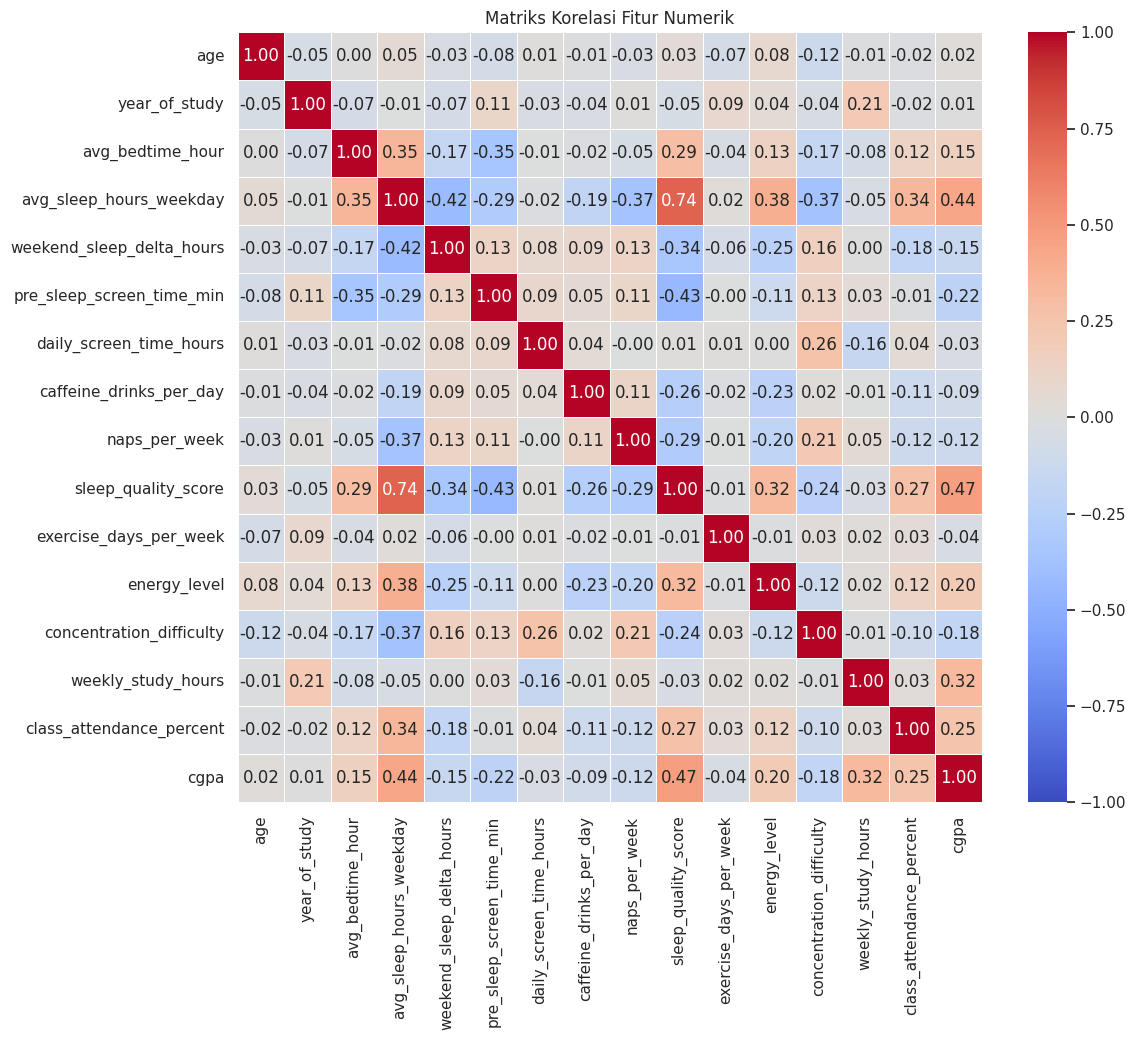

In [48]:
plt.figure(figsize=(12, 10))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5,
    vmin=-1.0, vmax=1.0
)
plt.title('Matriks Korelasi Fitur Numerik')
plt.savefig("/kaggle/working/corr_matrix.png")
plt.show()

3. Perhatikan matriks korelasi fitur di atas! Bagaimana interpretasimu terhadap matriks korelasi berikut?
   -
   Jawab: Menurut saya, jika nilai korelasi semakin tinggi (mendekati 1) maka korelasi antar dua kolom semakin erat, jika satu naik, yang lain ikut naik. Misalnya kolom **avg_sleep_hours_weekday** dengan kolom **sleep_quality_score** yang nilai korelasinya bernilai 0,74. Karena 0,74 itu mendekati 1, maka ketika nilai avg_sleep_hours_weekday naik kemungkinan besar nilai sleep_quality_score juga ikut naik.

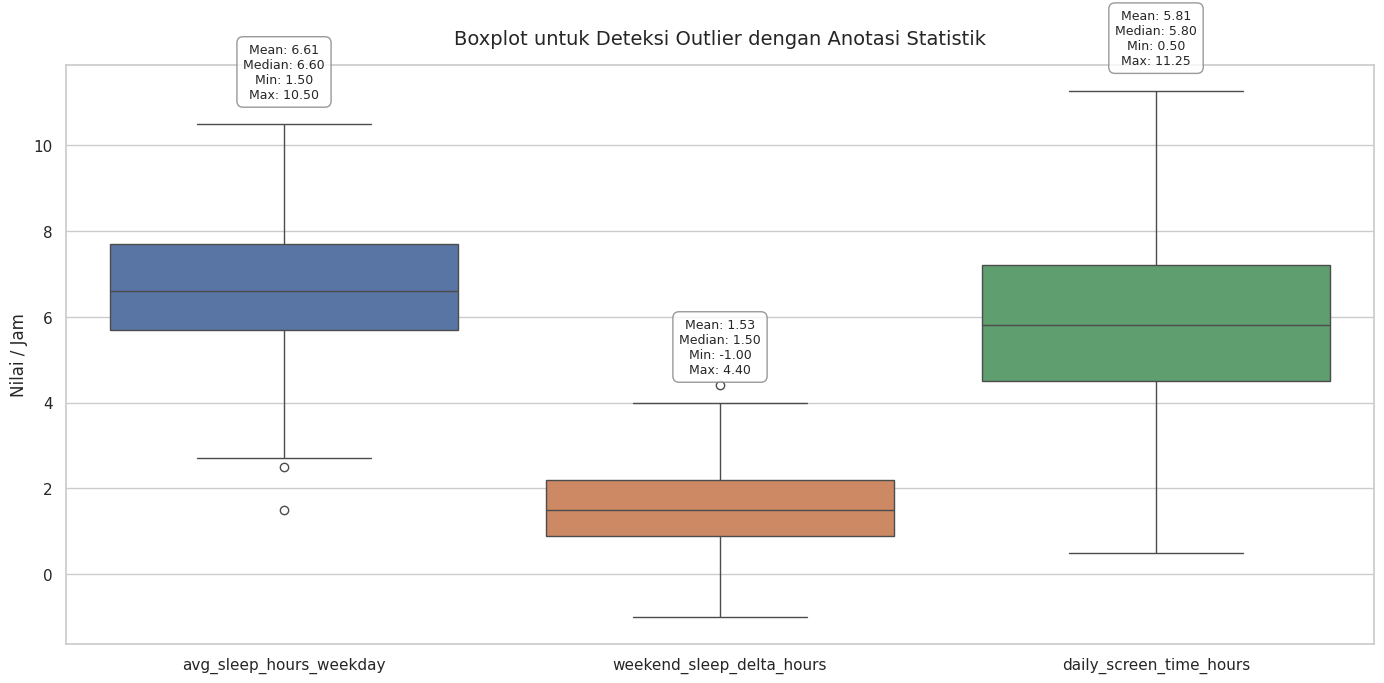

In [49]:
cols = ['avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'daily_screen_time_hours']

plt.figure(figsize=(14, 7))
ax = sns.boxplot(data=df[cols])
plt.title('Boxplot untuk Deteksi Outlier dengan Anotasi Statistik', fontsize=14, pad=15)
plt.ylabel('Nilai / Jam')

for i, col in enumerate(cols):
    mean_val = df[col].mean()
    median_val = df[col].median()
    min_val = df[col].min()
    max_val = df[col].max()

    stats_text = (
        f"Mean: {mean_val:.2f}\n"
        f"Median: {median_val:.2f}\n"
        f"Min: {min_val:.2f}\n"
        f"Max: {max_val:.2f}"
    )
    
    # Menempatkan teks di atas masing-masing boxplot
    # i adalah posisi indeks sumbu X (0, 1, 2)
    # max_val * 1.05 digunakan agar teks berada sedikit di atas titik maksimum/whisker
    ax.text(
        x=i, 
        y=df[col].max() * 1.05, 
        s=stats_text, 
        horizontalalignment='center', 
        verticalalignment='bottom', 
        fontsize=9,
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.savefig("/kaggle/working/boxplot.png")
plt.show()

https://www.geeksforgeeks.org/data-analysis/box-plot/

4. Apa interpretasimu terhadap grafik *boxplot* di atas?
   -
   Jawab: Saya ambil contoh untuk kolom **avg_sleep_hours_weekday**, nilai max-nya di angka 10.50 jam dan nilai min-nya di angka 1.50 jam. Sebanyak 50% student tidur kurang dari atau sama dengan 6.60 jam, dan 50% sisanya tidur lebih dari 6.60 jam. Batas atas mencapai 10.50 jam dan batas bawah berada dikisaran 2.7 jam. Terdapat 2 titik lingkaran di bawah batas bawah (sekitar nilai 2.5 jam dan 1.5 jam). Outlier tersebut merupakan student yang memiliki pola tidur sangat rendah pada weekday.

5. Load ulang dataset dan simpan ke variabel 'df_tugas'!
   -

In [50]:
# Jawab : . . . 
# Tulis kode di sini . . .
df_tugas = pd.read_csv('/kaggle/input/datasets/aamir28/student-sleep-screen-time-and-academic-performance/student_sleep_screen_time_academic_performance.csv')

df_tugas

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,STU2496,18,Male,4,Humanities,Dormitory,Intermediate,22.5,7.5,0.4,...,0,8.0,4,7.0,4.0,10.1,90.8,No,Fall,3.21
496,STU2497,22,Male,2,Health Sciences,Dormitory,Night Owl,0.8,6.2,2.4,...,2,10.0,4,6.0,5.0,17.2,70.7,No,Spring,2.87
497,STU2498,20,Female,5,Health Sciences,With Family,Early Bird,22.0,7.1,1.1,...,3,10.0,1,8.0,2.0,21.7,79.8,No,Spring,3.54
498,STU2499,22,M,3,STEM,Dormitory,Early Bird,23.6,9.0,2.3,...,0,10.0,7,7.0,1.0,19.3,97.8,Yes,Spring,3.67


In [51]:
df_tugas.info()
df_tugas.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    object 
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    object 
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    object 
 5   residence_type             500 non-null    object 
 6   chronotype                 500 non-null    object 
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    object 
 13  device_free_before_bed     491 non-null    object 

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,cgpa
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,494.000000,500.000000,485.000000,486.000000,500.0000,500.000000,493.000000
mean,20.260000,2.954000,12.778200,6.608200,1.540600,38.388000,5.827000,1.502000,1.458000,7.271255,3.666000,5.758763,5.176955,16.5714,79.247200,2.833834
std,1.994079,1.405644,10.772656,1.435784,0.965441,23.573478,2.046193,1.273279,1.331082,2.131409,2.277019,1.981722,2.033119,6.9279,11.983513,0.334771
min,17.000000,1.000000,0.000000,1.500000,-1.000000,0.000000,0.500000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.0000,34.600000,1.890000
25%,19.000000,2.000000,1.100000,5.700000,0.900000,22.000000,4.475000,1.000000,0.000000,6.000000,2.000000,4.000000,4.000000,12.1000,70.775000,2.620000
50%,20.000000,3.000000,21.500000,6.600000,1.500000,35.500000,5.800000,1.000000,1.000000,7.000000,4.000000,6.000000,5.000000,16.3000,79.800000,2.850000
75%,22.000000,4.000000,22.800000,7.700000,2.200000,54.000000,7.200000,2.000000,2.000000,9.000000,6.000000,7.000000,7.000000,20.3250,87.925000,3.050000
max,27.000000,5.000000,24.000000,10.500000,4.400000,240.000000,19.500000,7.000000,7.000000,10.000000,7.000000,10.000000,10.000000,88.5000,100.000000,3.950000


6. Pisahkan kolom menjadi fitur $X_{tugas}$ dan target $y_{tugas}$!
   -

In [52]:
# Jawab : . . . 
# Tulis kode di sini . . .

X_tugas = df_tugas.drop(columns=['cgpa'])
y_tugas = df_tugas['cgpa']

7. Buat data latih dan data uji dengan proporsi $75:25$ dan random_state=42 serta shuffle=True ($75\%$ data latih dan $25\%$ data uji)! Simpan di variabel X_train_tugas, X_test_tugas, y_train_tugas, dan y_test_tugas!
   -

In [53]:
# Jawab : . . . 
# Tulis kode di sini . . .
X_train, X_test, y_train, y_test = train_test_split(
    X_tugas, y_tugas, test_size=0.2, random_state=42, shuffle=True
)

8. Lakukan *exploratory data analysis* pada df_tugas: fitur mana saja yang memiliki *missing value*?
   -
   Jawab: fitur **device_free_before_bed**, **sleep_quality_score**, **energy_level**, dan **concentration_difficulty**

In [54]:
df_tugas.isnull().sum()

student_id                    0
age                           0
gender                        0
year_of_study                 0
major_category                0
residence_type                0
chronotype                    0
avg_bedtime_hour              0
avg_sleep_hours_weekday       0
weekend_sleep_delta_hours     0
pre_sleep_screen_time_min     0
daily_screen_time_hours       0
primary_device                0
device_free_before_bed        9
caffeine_drinks_per_day       0
naps_per_week                 0
sleep_quality_score           6
exercise_days_per_week        0
energy_level                 15
concentration_difficulty     14
weekly_study_hours            0
class_attendance_percent      0
has_part_time_job             0
semester_type                 0
cgpa                          7
dtype: int64

9. Lakukan *data preprocessing* pada data latih: lakukan imputasi pada kolom yang memiliki *missing value*?
   -

In [55]:
# device_free_before_bed --> object
# sleep_quality_score, energy_level, dan concentration_difficulty --> float

# untuk fitur numerik, biasanya diisi pake median
# cara 1 (kalo cuman satu kolom)
df_tugas['sleep_quality_score'] = df_tugas['sleep_quality_score'].fillna(df_tugas['sleep_quality_score'].median())
# cara 2 (kalo banyak kolom)
fitur_numerik_nan = ['energy_level', 'concentration_difficulty']

for col in fitur_numerik_nan:
    if col in df_tugas.columns and df_tugas[col].isnull().sum() > 0:
        median_val = df_tugas[col].median()
        df_tugas[col] = df_tugas[col].fillna(median_val)
        
        print(f"Imputasi kolom {col} dengan median: {median_val}")

# untuk fitur kategorikal, biasanya diisi pake modus
df_tugas['device_free_before_bed'] = df_tugas['device_free_before_bed'].fillna(
    df_tugas['device_free_before_bed'].mode()[0]
)

print(
    '\nSisa missing value setelah imputasi:',
    df_tugas.isnull().sum().sum(),
    '\n',
)

Imputasi kolom energy_level dengan median: 6.0
Imputasi kolom concentration_difficulty dengan median: 5.0

Sisa missing value setelah imputasi: 7 



Hint: gunakan SimpleImputer dari Scikit-Learn untuk melakukan fit_transform imputasi pada data latih! Jika kesulitan, cukup gunakan cara seperti di atas.
<br>
*many roads lead to Roma~~~*

10. Lakukan EDA pada df_tugas: fitur mana saja yang berkorelasi kuat dengan cgpa?
    -
   Jawab: . . .

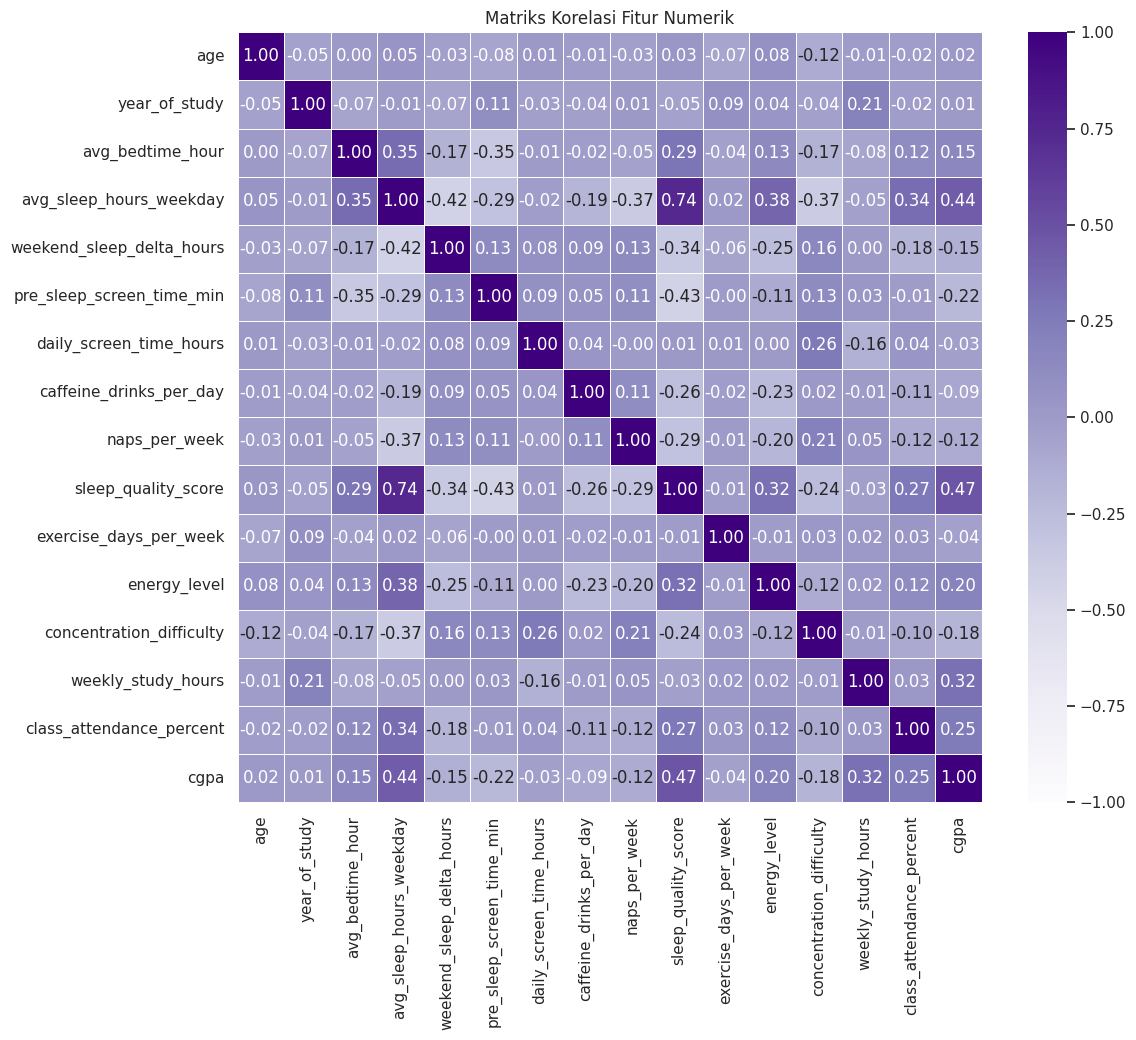

In [56]:
new_numeric_cols = df_tugas.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[new_numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='Purples', fmt='.2f',
           linewidths=0.5, vmin=-1.0, vmax=1.0)

plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

11. Lakukan EDA pada df_tugas: apakah ada multikolinearitas pada data latih? Jelaskan alasannya!
    -
    Jawab: . . .

12. Lakukan EDA pada df_tugas: fitur mana saja yang mengalami *skewness*?
    -
    Jawab: . . .

In [57]:
# Tulis kode di sini . . .

13. Lakukan EDA pada df_tugas: sebutkan fitur nominal dan fitur ordinal!
    -
    Jawab: . . .

In [58]:
# Tulis kode di sini . . .

14. Lakukan *data preprocessing* pada data latih: lakukan transformasi untuk fitur yang *skew*!
    -

In [59]:
# Jawab: . . .
# Tulis kode di sini . . .

15. Lakukan *data preprocessing* pada data latih: lakukan *encoding* pada data kategorikal!
    -

In [60]:
# Jawab: . . .
# Tulis kode di sini . . .

16. Lakukan *data preprocessing* pada data latih: lakukan penskalaan fitur!
    -

In [61]:
# Jawab: . . .
# Tulis kode di sini . . .

17. Bonus Challenge: lakukan *data preprocessing* pada data uji!
    -
    Hint: gunakan fit_transform() pada data latih dan transform() pada data uji.

In [62]:
# Jawab: . . .
# Tulis kode di sini . . .